# Wumpus World with Q-learning on macro-actions

**Idea.** A Q-table over `(row, col, ...)` only memorises *one* map, and a Q-table over raw percepts doesn't know *where* it is.
We split the problem in two:

1. **Logic does the bookkeeping.** The agent remembers where it felt a breeze or a stench and marks every unexplored cell next to the explored area as
   `safe`, `P` (could be a pit), `W` (could be the Wumpus) or `PW` (could be either).
2. **Q-learning makes the decisions.** It chooses between 4 *macro-actions*:
   - `EXPLORE`: walk to the nearest **safe** unexplored cell
   - `RISK`: walk to the least dangerous **unsafe** cell
   - `SHOOT`: walk next to a possible Wumpus cell and shoot the arrow at it
   - `HOME`: walk back to the start (0,0) and climb out (this ends the game)

The **state** is only `(has_gold, best_frontier_cell, has_arrow)`, which gives 2 × 5 × 2 = 20 states.
It doesn't contain coordinates, so **the same Q-table works on any board size**.

**Rules** (Russell & Norvig): random maps, every cell except (0,0) has a pit with p = 0.2, one Wumpus, one gold.
Rewards: −1 per move, −1 grab, −10 arrow, −1000 death, +1000 leaving the cave with the gold. No reward shaping.

In [ ]:
import random
from collections import defaultdict, deque
from copy import deepcopy
import matplotlib.pyplot as plt

N = 4   # board size

MOVES = [(1, 0), (-1, 0), (0, 1), (0, -1)]
EXPLORE, RISK, SHOOT, HOME = range(4)
NAMES = ['EXPLORE', 'RISK', 'SHOOT', 'HOME']
RANK = {'safe': 0, 'W': 1, 'P': 2, 'PW': 3}  # how scary a frontier cell is

## The world

In [2]:
def neighbors(cell, n):
    r, c = cell
    return [(r + dr, c + dc) for dr, dc in MOVES if 0 <= r + dr < n and 0 <= c + dc < n]


def new_game(n, pit_prob=0.2):
    cells = [(r, c) for r in range(n) for c in range(n) if (r, c) != (0, 0)]
    pits = {x for x in cells if random.random() < pit_prob}
    g = dict(n=n, pits=pits, wumpus=random.choice(cells),
             gold=random.choice([x for x in cells if x not in pits] or cells),
             visited=set(), breeze=set(), stench=set(), no_wumpus=set(),
             has_gold=False, arrow=True, wumpus_alive=True, alive=True, done=False, score=0)
    enter(g, (0, 0))
    return g


def enter(g, cell):
    """Agent arrives in `cell`: it dies, or it perceives breeze/stench and grabs gold."""
    g['pos'] = cell
    g['visited'].add(cell)
    if cell in g['pits'] or (cell == g['wumpus'] and g['wumpus_alive']):
        g['score'] -= 1000
        g['alive'], g['done'] = False, True
        return
    near = neighbors(cell, g['n'])
    if any(x in g['pits'] for x in near):
        g['breeze'].add(cell)
    if g['wumpus'] in near:
        g['stench'].add(cell)
    if cell == g['gold'] and not g['has_gold']:
        g['has_gold'] = True
        g['score'] -= 1  # GRAB

## What the agent knows (simple logic)
A cell can't hold a pit if **any** explored neighbour has no breeze. Stench and the Wumpus work the same way.
A missed arrow also proves that the Wumpus isn't in the cells it flew through.

In [3]:
def frontier(g):
    """Unvisited cells next to visited ones, labelled 'safe', 'P', 'W' or 'PW' by simple logic."""
    def maybe_pit(x):  # a pit is excluded by ANY visited neighbour without breeze
        return all(v in g['breeze'] for v in neighbors(x, g['n']) if v in g['visited'])

    def maybe_wumpus(x):
        if not g['wumpus_alive'] or x in g['no_wumpus']:
            return False
        return all(v in g['stench'] for v in neighbors(x, g['n']) if v in g['visited'])

    cells = {x for v in g['visited'] for x in neighbors(v, g['n']) if x not in g['visited']}
    return {x: ('P' if maybe_pit(x) else '') + ('W' if maybe_wumpus(x) else '') or 'safe' for x in cells}


def distance(g, a, b):
    """Steps from a to b walking only on visited (= safe) cells."""
    dist, queue = {a: 0}, deque([a])
    while queue:
        x = queue.popleft()
        if x == b:
            return dist[x]
        for y in neighbors(x, g['n']):
            if y not in dist and (y in g['visited'] or y == b):
                dist[y] = dist[x] + 1
                queue.append(y)


def nearest(g, cells):
    return min(cells, key=lambda x: (distance(g, g['pos'], x), random.random()))

## State and macro-actions

In [4]:
def state(g):
    """What Q-learning sees: 2 x 5 x 2 = 20 states, independent of the board size."""
    best = min(frontier(g).values(), key=RANK.get, default='none')
    return g['has_gold'], best, g['arrow']


def valid_actions(g):
    kinds = set(frontier(g).values())
    acts = [HOME]
    if 'safe' in kinds:
        acts.append(EXPLORE)
    if kinds - {'safe'}:
        acts.append(RISK)
    if g['arrow'] and any('W' in k for k in kinds):
        acts.append(SHOOT)
    return acts


def step(g, action):
    """Run one macro-action; returns its total reward (-1 per move, -10 arrow, +-1000)."""
    before, f = g['score'], frontier(g)
    if action == HOME:
        g['score'] -= distance(g, g['pos'], (0, 0))
        g['pos'] = (0, 0)
        g['score'] += 1000 if g['has_gold'] else 0
        g['done'] = True
    elif action in (EXPLORE, RISK):
        if action == EXPLORE:
            targets = [x for x, k in f.items() if k == 'safe']
        else:
            least = min(RANK[k] for k in f.values() if k != 'safe')
            targets = [x for x, k in f.items() if RANK[k] == least]
        target = nearest(g, targets)
        g['score'] -= distance(g, g['pos'], target)
        enter(g, target)
    elif action == SHOOT:
        target = nearest(g, [x for x, k in f.items() if 'W' in k])
        shooter = nearest(g, [v for v in neighbors(target, g['n']) if v in g['visited']])
        g['score'] -= distance(g, g['pos'], shooter) + 10
        g['pos'], g['arrow'] = shooter, False
        dr, dc = target[0] - shooter[0], target[1] - shooter[1]
        x = target
        while 0 <= x[0] < g['n'] and 0 <= x[1] < g['n']:  # the arrow flies straight
            if x == g['wumpus']:
                g['wumpus_alive'] = False  # scream!
                break
            g['no_wumpus'].add(x)
            x = (x[0] + dr, x[1] + dc)
    return g['score'] - before

## Q-learning
Normal tabular Q-learning: ε-greedy with linear decay, small α because outcomes are random (each map is different), γ = 1 because
games are short and every move already costs −1.

In [5]:
def greedy(Q, s, acts):
    return max(acts, key=lambda a: (Q[s, a], random.random()))


def train(episodes, n=4, alpha=0.01, gamma=1.0):
    Q = defaultdict(float)
    for e in range(episodes):
        epsilon = max(0.05, 1 - e / (0.7 * episodes))
        g = new_game(n)
        s = state(g)
        while not g['done']:
            acts = valid_actions(g)
            a = random.choice(acts) if random.random() < epsilon else greedy(Q, s, acts)
            r = step(g, a)
            if g['done']:
                target = r
            else:
                s2 = state(g)
                target = r + gamma * max(Q[s2, b] for b in valid_actions(g))
            Q[s, a] += alpha * (target - Q[s, a])
            if not g['done']:
                s = s2
    return Q

In [6]:
random.seed(42)
Q = train(50_000, n=N)

print(f"{'state (gold, best cell, arrow)':32} " + ' '.join(f'{a:>8}' for a in NAMES))
for s in sorted({s for s, _ in Q}):
    print(f'{str(s):32} ' + ' '.join(f'{Q[s, a]:8.0f}' if (s, a) in Q else f"{'':>8}" for a in range(4)))

state (gold, best cell, arrow)    EXPLORE     RISK    SHOOT     HOME
(False, 'P', False)                           -432                -3
(False, 'P', True)                            -389       -8       -0
(False, 'PW', True)                           -604      -11       -0
(False, 'W', False)                           -515                -2
(False, 'W', True)                            -474      470       -1
(False, 'safe', False)                532     -786                -2
(False, 'safe', True)                 661     -565      473       -1
(True, 'P', False)                            -230               959
(True, 'P', True)                             -174       41      996
(True, 'PW', False)                              0                10
(True, 'PW', True)                             -10       14      245
(True, 'W', False)                            -131               713
(True, 'W', True)                             -175      158      979
(True, 'none', False)             

**Reading the table:** the agent learned to
- `EXPLORE` while a safe cell exists
- `SHOOT` when the only unknown cells might hide the Wumpus
- go `HOME` as soon as it has the gold
- **never** take a pit risk (`RISK` ≈ −400 vs `HOME` ≈ 0), because one gamble costs more than the gold is worth.

## Evaluation on fresh random maps, different board sizes

In [7]:
def play(policy, n):
    g = new_game(n)
    while not g['done']:
        step(g, policy(g))
    return g


def solvable(g):
    """Upper bound: can the gold be reached at all without walking on a pit?"""
    seen, queue = {(0, 0)}, deque([(0, 0)])
    while queue:
        x = queue.popleft()
        for y in neighbors(x, g['n']):
            if y not in seen and y not in g['pits']:
                seen.add(y)
                queue.append(y)
    return g['gold'] in seen


def evaluate(policy, n, games=5000, seed=0):
    random.seed(seed)
    results = [play(policy, n) for _ in range(games)]
    wins = sum(g['alive'] and g['has_gold'] for g in results)
    deaths = sum(not g['alive'] for g in results)
    random.seed(seed)
    possible = sum(solvable(new_game(n)) for _ in range(games))
    return 100 * wins / games, 100 * deaths / games, sum(g['score'] for g in results) / games, 100 * possible / games



policies = {
    'random': lambda g: random.choice(valid_actions(g)),
    'cautious (hand-made)': lambda g: EXPLORE if EXPLORE in valid_actions(g) and not g['has_gold'] else HOME,
    'Q-learning': lambda g: greedy(Q, state(g), valid_actions(g)),
}
print(f"{'board':6} {'agent':22} {'win %':>6} {'death %':>8} {'avg score':>10} {'solvable %':>11}")
for n in (4, 5, 6, 8):
    for name, p in policies.items():
        w, d, sc, pos = evaluate(p, n)
        print(f'{n}x{n:<4} {name:22} {w:6.1f} {d:8.1f} {sc:10.1f} {pos:11.1f}')

board  agent                   win %  death %  avg score  solvable %


4x4    random                    3.6     23.5     -201.3        89.8


4x4    cautious (hand-made)     29.6      0.0      290.9        89.8


4x4    Q-learning               39.8      0.0      389.9        89.8


5x5    random                    1.9     22.4     -206.8        90.0


5x5    cautious (hand-made)     27.0      0.0      263.8        90.0


... (3 outputs left out)

6x6    Q-learning               26.0      0.0      248.9        89.1


8x8    random                    1.0     20.7     -198.6        90.6


8x8    cautious (hand-made)     16.5      0.0      153.6        90.6


8x8    Q-learning               17.7      0.0      164.2        90.6


`solvable %` is the share of maps where the gold can be reached at all without stepping on a pit (an upper bound for the win rate).
The Q-table was trained **only on 4×4** but still works on bigger boards.

## Watching the agent play
Black = pit, red X = Wumpus (empty X = dead), star = gold, blue dot = agent.
Green cells are explored, grey cells are unknown to the agent. B/S = breeze/stench felt in that cell.

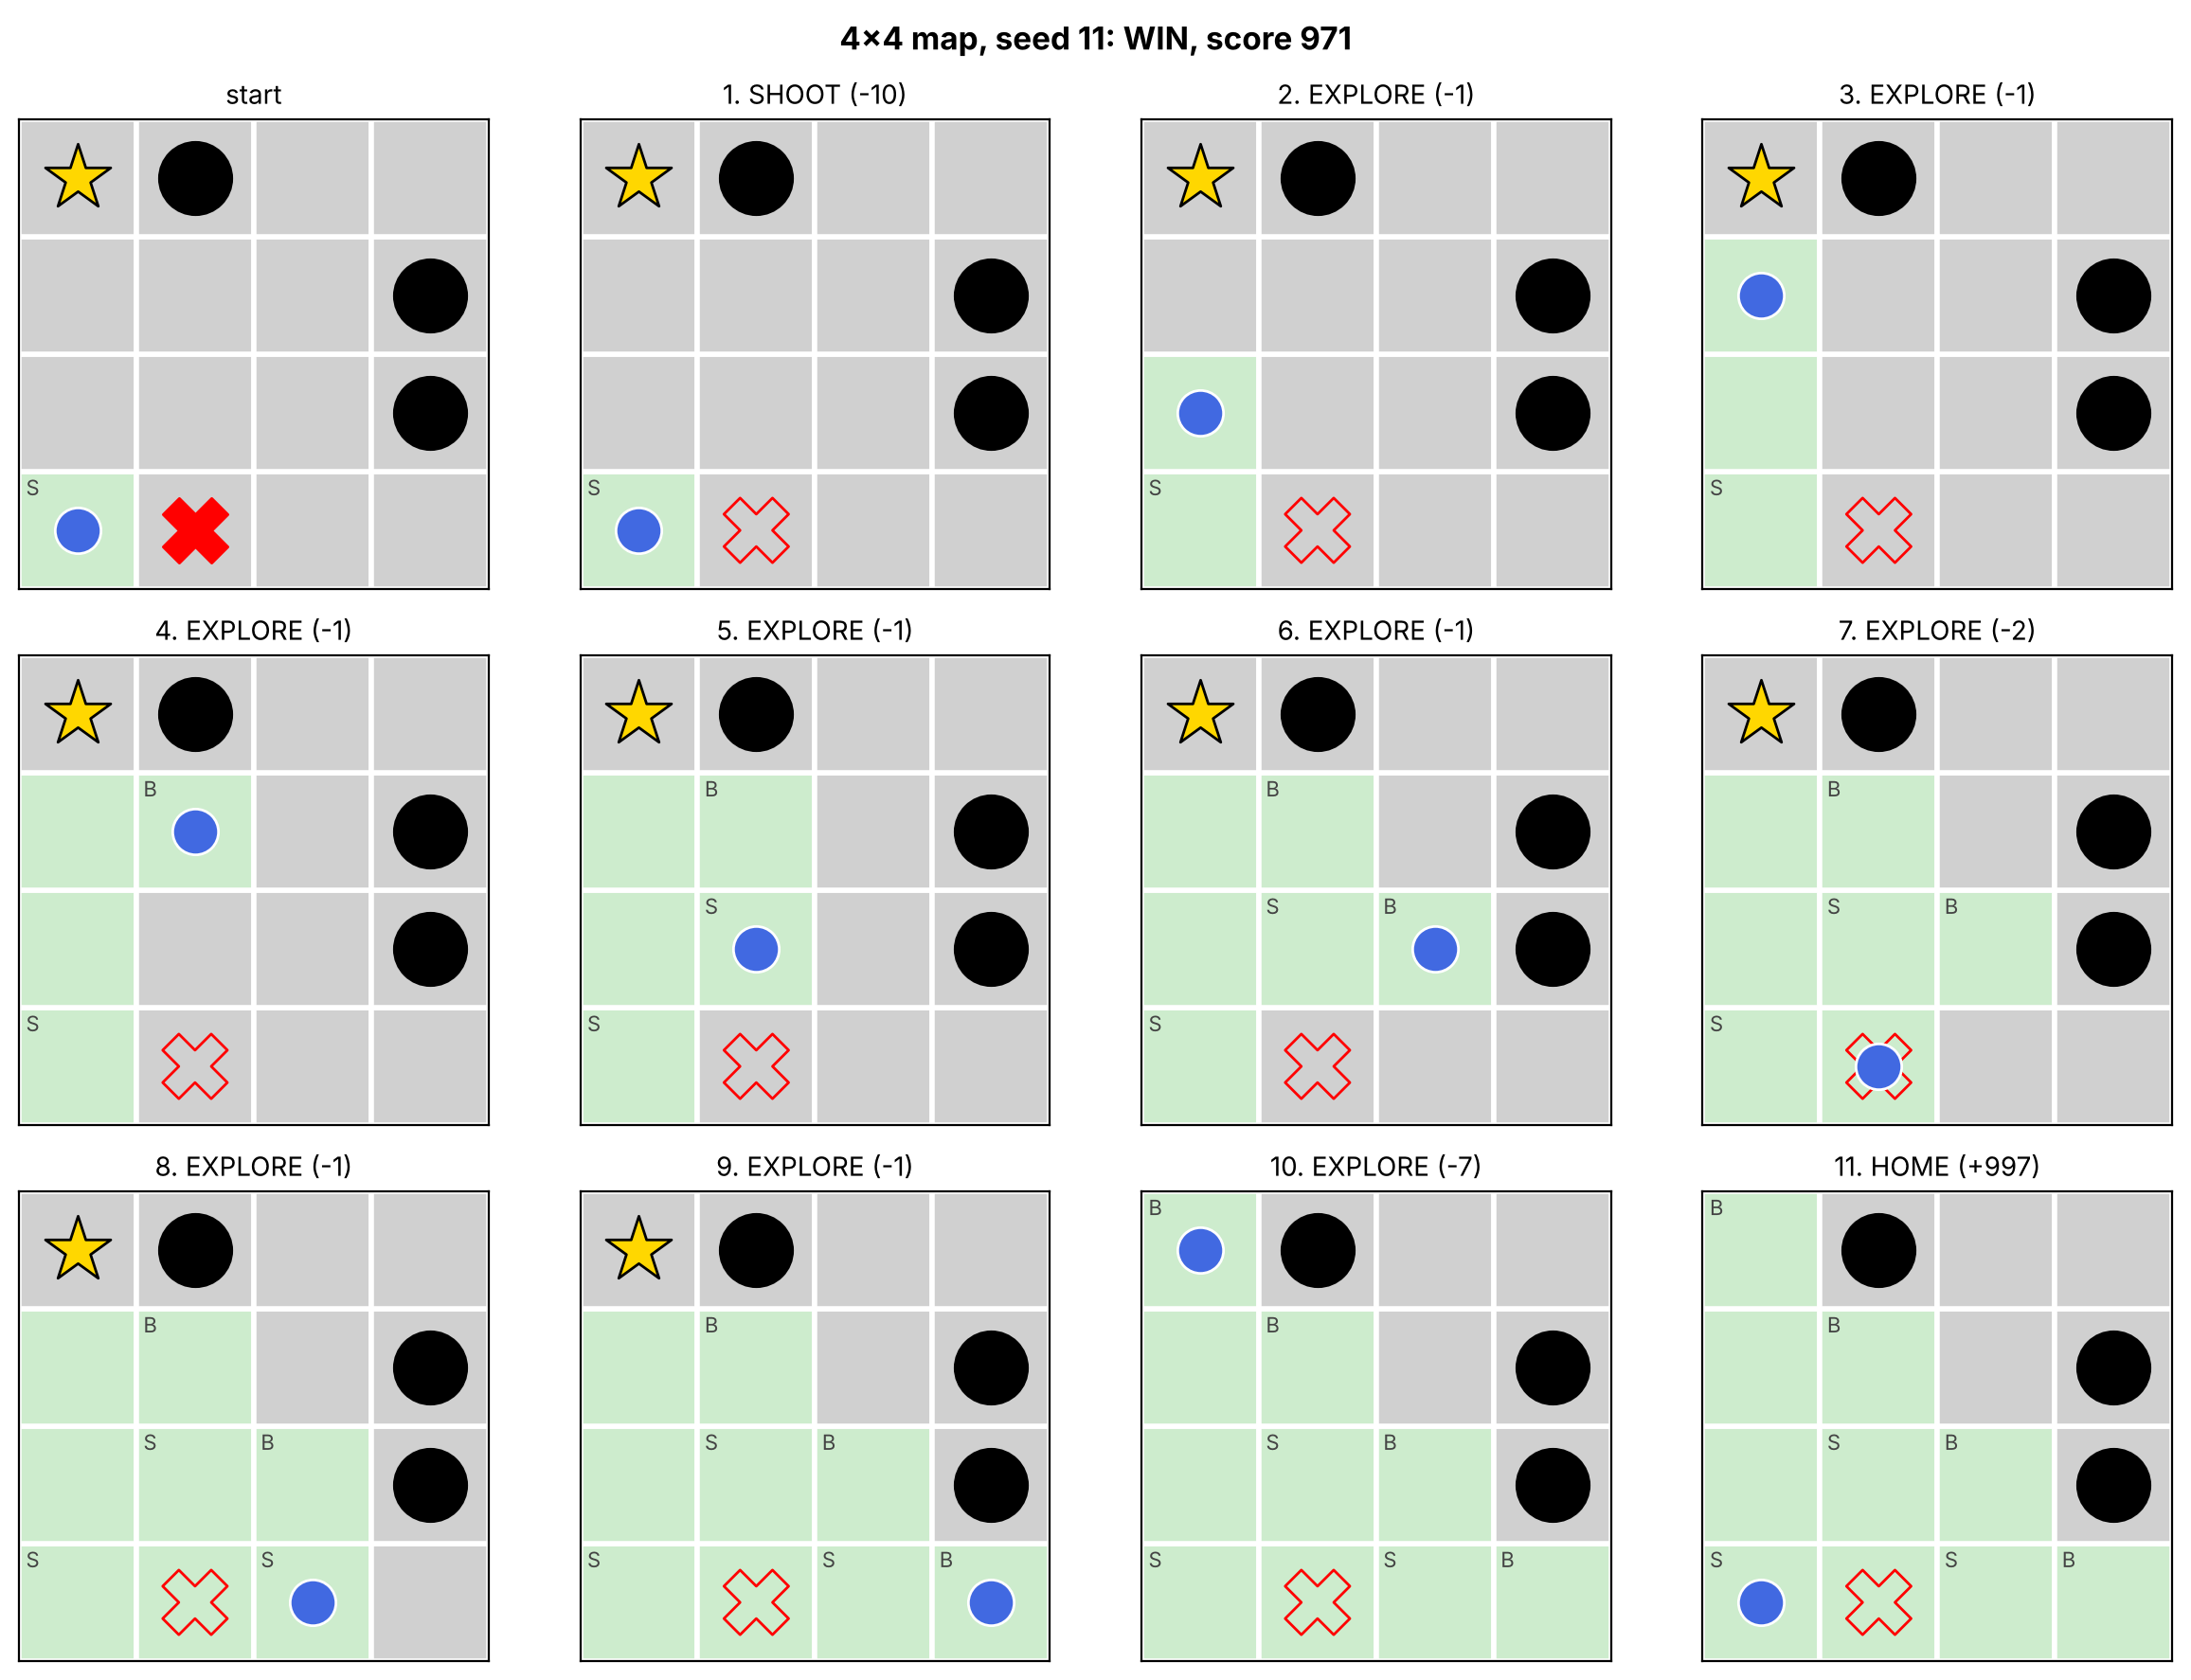

In [8]:
def draw(g, ax, title=''):
    """Green = explored, grey = unknown, B/S = breeze/stench felt there."""
    n, k = g['n'], (110 / g['n']) ** 2
    for r in range(n):
        for c in range(n):
            ax.add_patch(plt.Rectangle((c, r), 1, 1, ec='white', lw=2,
                                       fc='#cdeccd' if (r, c) in g['visited'] else '#d0d0d0'))
            ax.text(c + .06, r + .8, ('B' if (r, c) in g['breeze'] else '') + ('S' if (r, c) in g['stench'] else ''),
                    fontsize=8, color='#444')

    def mark(cells, **kw):
        ax.scatter([c + .5 for r, c in cells], [r + .5 for r, c in cells], **kw)

    mark(g['pits'], s=k, c='black')
    mark([g['wumpus']], s=.8 * k, marker='X', c='red' if g['wumpus_alive'] else 'none', edgecolors='red')
    if not g['has_gold']:
        mark([g['gold']], s=.9 * k, marker='*', c='gold', edgecolors='black')
    mark([g['pos']], s=.4 * k, c='royalblue', edgecolors='white', zorder=3)
    ax.set(xlim=(0, n), ylim=(0, n), xticks=[], yticks=[], aspect='equal')
    ax.set_title(title, fontsize=10)



def replay(seed, n=N, cols=4):
    random.seed(seed)
    g = new_game(n)
    frames = [(deepcopy(g), 'start')]
    while not g['done']:
        a = greedy(Q, state(g), valid_actions(g))
        r = step(g, a)
        frames.append((deepcopy(g), f'{len(frames)}. {NAMES[a]} ({r:+})'))
    rows = -(-len(frames) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, (snap, title) in zip(axes.flat, frames):
        ax.axis('on')
        draw(snap, ax, title)
    result = 'WIN' if g['alive'] and g['has_gold'] else 'DEAD' if not g['alive'] else 'left without gold'
    fig.suptitle(f'{n}x{n} map, seed {seed}: {result}, score {g["score"]}', fontweight='bold')
    plt.tight_layout()
    plt.show()


replay(11)

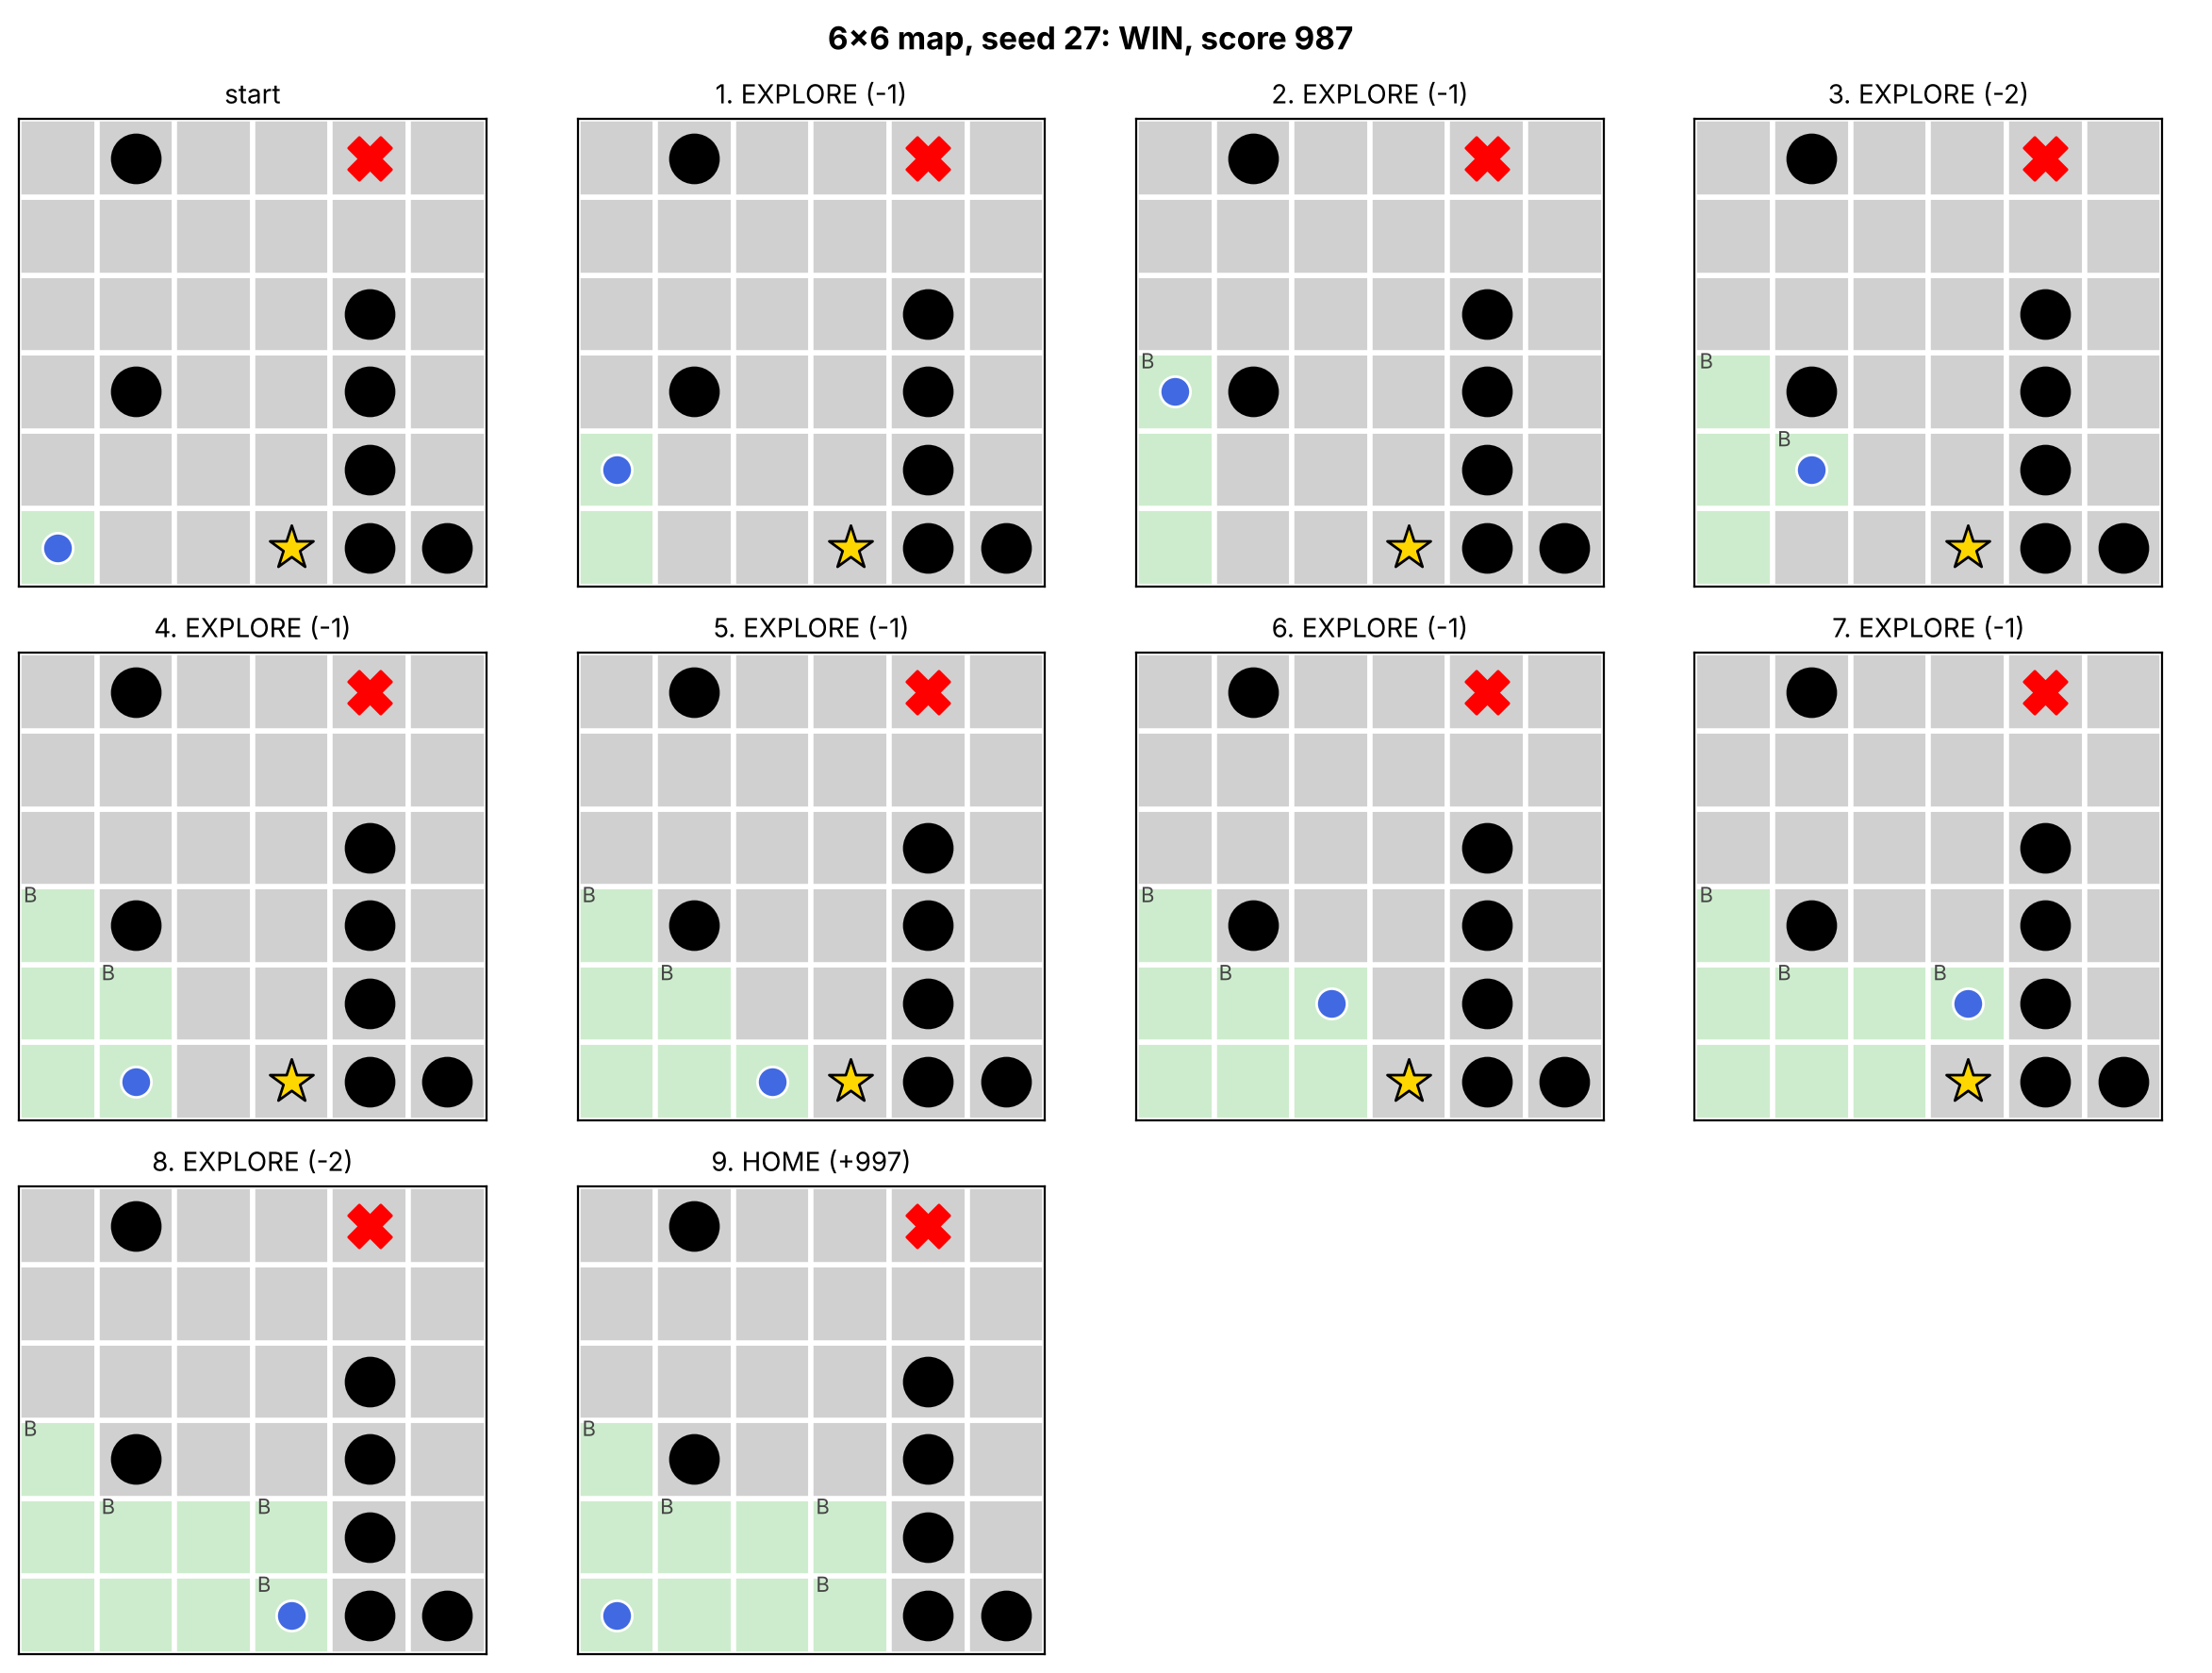

In [9]:
replay(27, n=6)  # same Q-table, bigger board: try other seeds and sizes